# ITRI625 Project: Phishing Email Detection with a BiLSTM

**Goal:** classify an email (subject + body) as **phishing/malicious (1)** or **legitimate (0)**, then serve the model through a FastAPI endpoint and a Tkinter desktop app.

| Rubric item | Where in this notebook |
|---|---|
| 2.1 Model development | Sections 3–9 (preprocessing, TF-IDF baseline, BiLSTM) |
| 2.2 Train / validation / test split | Section 6 |
| 2.3 Metric logging after every epoch | Section 9 (`metrics_log`, also saved to `results/metrics_log.csv`) |
| 2.4 Metric graphs (Matplotlib) | Sections 5, 10 |
| 2.5 API + desktop app | Section 11 saves the model; see `api/main.py` and `app/desktop_app.py` |
| 2.6 Patience / early stopping | Section 9 (`EarlyStopping` class) |
| 2.7 Additional features | Section 13 (XAI: LR coefficients, occlusion, LIME), threshold tuning, baseline comparison, Docker hosting |

> **Shared code.** The text-cleaning and model code is written in this notebook with `%%writefile` cells (Sections 3 and 8). The cells write it into `phishing_core/` so the API loads the **exact same** code. Edit the code here, not in the `.py` files.

## 1. Setup

In [1]:
import sys, time, random, json, importlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             log_loss)
import joblib

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Paths work on Windows/Mac/Linux as long as the notebook is run from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, MODEL_DIR = ROOT / "data", ROOT / "models"
RESULTS_DIR, FIG_DIR = ROOT / "results", ROOT / "results" / "figures"
for d in (MODEL_DIR, RESULTS_DIR, FIG_DIR, ROOT / "phishing_core"):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__}")
print("Project root:", ROOT)
print("Device:", DEVICE)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | torch 2.14.1+cu130
Project root: /home/claude/proj
Device: cpu


## 2. Load the data

The data comes from the Kaggle *Phishing Email Dataset* collection (Al-Subaiey et al., 2024). Our goal is **phishing** detection, not general spam filtering, so each file is used deliberately:

| File | What it contains | What we take |
|---|---|---|
| `Nazario.csv` | Real phishing emails collected by Jose Nazario (2015–2022): fake banks (incl. Standard Bank, Nedbank), password resets, mailbox-full scams | **all** → phishing (1) |
| `Nigerian_Fraud.csv` | Advance-fee ("419") fraud emails | **all** → phishing (1) |
| `CEAS_08.csv` | 2008 spam-filter challenge: mostly spam + legitimate mailing-list mail | **legitimate only** (0) |
| `SpamAssasin.csv` | SpamAssassin public corpus: spam + legitimate mail | **legitimate only** (0) |
| `Ling.csv` | Ling-Spam: spam + legitimate academic mailing-list mail | **legitimate only** (0) |

**Why drop the spam?** Spam (pharmacy ads, replica watches) is not phishing. If spam stays in the positive class, the model learns to spot *advertising* instead of *credential theft and fraud*. Our first version had exactly this problem: it missed a fake PayPal email.

**Why legitimate mail from three different corpora?** All the phishing comes from Nazario and Nigerian_Fraud. If all the legitimate mail came from one corpus, the model could learn to tell the *datasets* apart (their formatting, era and topics) instead of phishing from legitimate. Mixing three sources of legitimate mail reduces this **shortcut learning**.

**Removing a collection artefact.** Every Nazario email was sent to the collector's own mailbox (*jose@monkey.org*), so words like "jose" and "monkey" appear in almost every phishing email and in no legitimate ones. A model would happily learn "jose = phishing". We replace these names with a neutral word before training.

Files are found anywhere under `data/` (e.g. `data/archive/` after unzipping the Kaggle download). `phishing_email.csv` (a pre-merged copy of everything) and `Enron.csv` are not used.

Label convention: `1` = phishing/fraud, `0` = legitimate.

In [2]:
import re

# file stem -> which rows to use: "all" = keep every row, "legit" = keep only label-0 rows
SOURCES = {
    "Nazario": "all",
    "Nigerian_Fraud": "all",
    "CEAS_08": "legit",
    "SpamAssasin": "legit",
    "Ling": "legit",
}
# The Nazario mailbox owner's name/domain appears in nearly every phishing email: mask it (see text above)
ARTEFACT_RE = re.compile(r"jose\s*@\s*monkey\.org|monkey\.org|\bjose\b|\bnazario\b|\bmonkey\b", re.IGNORECASE)

def find_csv(data_dir, stem):
    hits = sorted(data_dir.rglob(f"{stem}.csv"), key=lambda p: len(p.parts))
    return hits[0] if hits else None

def load_dataset(data_dir, sources):
    """Load each source, keep the requested rows, standardise to: source, subject, body, label."""
    frames, report = [], []
    for stem, keep in sources.items():
        path = find_csv(data_dir, stem)
        if path is None:
            print(f"  WARNING: {stem}.csv not found under {data_dir} - skipped"); continue
        df = pd.read_csv(path)
        cols = {c.lower(): c for c in df.columns}
        out = pd.DataFrame({
            "source": stem,
            "subject": df[cols["subject"]].fillna("").astype(str) if "subject" in cols else "",
            "body": df[cols["body"]].fillna("").astype(str),
            "label": pd.to_numeric(df[cols["label"]], errors="coerce"),
        }).dropna(subset=["label"])
        out["label"] = out["label"].astype(int)
        n_all = len(out)
        if keep == "legit":
            out = out[out["label"] == 0]
        if stem == "Nazario":
            out["subject"] = out["subject"].str.replace(ARTEFACT_RE, " recipient ", regex=True)
            out["body"] = out["body"].str.replace(ARTEFACT_RE, " recipient ", regex=True)
        report.append({"file": path.name, "rows in file": n_all, "rows used": len(out),
                       "used as": "phishing (1)" if keep == "all" else "legitimate (0)"})
        frames.append(out)
    display(pd.DataFrame(report))
    return pd.concat(frames, ignore_index=True)

raw = load_dataset(DATA_DIR, SOURCES)
print(f"Total: {len(raw):,} emails  |  phishing: {(raw.label == 1).sum():,}  |  legitimate: {(raw.label == 0).sum():,}")
raw.sample(5, random_state=SEED)[["source", "subject", "label"]]

,file,rows in file,rows used,used as
0,Nazario.csv,1565,1565,phishing (1)
1,Nigerian_Fraud.csv,3332,3332,phishing (1)
2,CEAS_08.csv,39154,17312,legitimate (0)
3,SpamAssasin.csv,5809,4091,legitimate (0)
4,Ling.csv,2859,2401,legitimate (0)


Total: 28,701 emails  |  phishing: 4,897  |  legitimate: 23,804


,source,subject,label
4974,CEAS_08,Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail/SpamAssassin/Util/R...,0
11509,CEAS_08,[cw-discuss] How to use IME in MS Office 2003?,0
27914,Ling,re : syldavian tutorial,0
4981,CEAS_08,[clamav-virusdb] Update (daily: 5739),0
27975,Ling,high desert linguistics society / students,0


## 3. Text preprocessing (shared with the API)

Each email is cleaned in the same way during training and inside the API:

1. Join the **subject and body** into one string, decode HTML entities and strip HTML tags.
2. Replace URLs with `urltoken`, e-mail addresses with `emailtoken` and numbers with `numtoken`. The model then learns *that* an email contains a link, not the specific domain, which goes stale fast.
3. Lowercase the text and remove punctuation, but keep `! ? $ %` as their own tokens. Urgency and money symbols are strong phishing signals.
4. Tokenise on whitespace. The vocabulary is built **from the training set only**, keeping the 25,000 most frequent words that occur at least twice. Unknown words map to `<unk>`.

In [3]:
%%writefile ../phishing_core/__init__.py
"""Shared code for the phishing email detector (written out by notebooks/02_model_training.ipynb)."""

Overwriting ../phishing_core/__init__.py


In [4]:
%%writefile ../phishing_core/text.py
"""Text cleaning, tokenisation and vocabulary for the phishing email detector.

This file is generated from notebooks/02_model_training.ipynb (%%writefile cell).
Edit it there and re-run the notebook so the notebook and the API stay in sync.
"""
import html
import json
import re
from collections import Counter
from pathlib import Path

URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
HTML_TAG_RE = re.compile(r"<[^>]+>")
NUM_RE = re.compile(r"\b\d+(?:[.,]\d+)*\b")
NON_WORD_RE = re.compile(r"[^a-z0-9$!?%\s]")
SPACE_RE = re.compile(r"\s+")

PAD, UNK = "<pad>", "<unk>"


def clean_text(subject, body) -> str:
    """Combine subject + body and normalise them into a single lowercase string.

    URLs, e-mail addresses and numbers are replaced with placeholder tokens so the
    model learns *that* a link is present rather than memorising specific domains.
    """
    subject = "" if subject is None or subject != subject else str(subject)  # handles NaN
    body = "" if body is None or body != body else str(body)
    text = f"{subject} {body}"
    text = html.unescape(text)
    text = HTML_TAG_RE.sub(" ", text)
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = text.lower()
    text = NUM_RE.sub(" numtoken ", text)
    text = NON_WORD_RE.sub(" ", text)
    # keep ! ? $ % as separate tokens - they are strong spam/phishing signals
    text = re.sub(r"([$!?%])", r" \1 ", text)
    return SPACE_RE.sub(" ", text).strip()


def tokenize(text: str) -> list:
    return text.split()


def count_urls(text) -> int:
    return len(URL_RE.findall(str(text or "")))


class Vocab:
    """Word -> integer index mapping, built on the TRAINING set only (no leakage)."""

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    @classmethod
    def build(cls, token_lists, max_size=25000, min_freq=2):
        counts = Counter(t for toks in token_lists for t in toks)
        words = [w for w, c in counts.most_common() if c >= min_freq][: max_size - 2]
        return cls([PAD, UNK] + words)

    def __len__(self):
        return len(self.itos)

    @property
    def pad_idx(self):
        return 0

    @property
    def unk_idx(self):
        return 1

    def encode(self, tokens, max_len=300):
        ids = [self.stoi.get(t, 1) for t in tokens[:max_len]]
        return ids if ids else [1]  # never return an empty sequence

    def save(self, path):
        Path(path).write_text(json.dumps(self.itos), encoding="utf-8")

    @classmethod
    def load(cls, path):
        return cls(json.loads(Path(path).read_text(encoding="utf-8")))

Overwriting ../phishing_core/text.py


In [5]:
import phishing_core.text as ptext
importlib.reload(ptext)
from phishing_core.text import clean_text, tokenize, Vocab, count_urls

example = raw.iloc[0]
print("SUBJECT:", example.subject)
print("RAW BODY:", str(example.body)[:300], "...")
print("\nCLEANED:", clean_text(example.subject, example.body)[:300], "...")

SUBJECT: DON'T DELETE THIS MESSAGE -- FOLDER INTERNAL DATA
RAW BODY: This text is part of the internal format of your mail folder, and is not a real message.  It is created automatically by the mail system software. If deleted, important folder data will be lost, and it will be re-created with the data reset to initial values. From 125117@ihp-osb-lngweb5.ihp.iinet.ne ...



CLEANED: don t delete this message folder internal data this text is part of the internal format of your mail folder and is not a real message it is created automatically by the mail system software if deleted important folder data will be lost and it will be re created with the data reset to initial values  ...


## 4. Cleaning and de-duplication

Merged email corpora contain many **exact duplicates**: newsletters, mass spam campaigns and re-sent messages. If a duplicate lands in both train and test, the test score measures memorisation rather than generalisation. This is **data leakage**, so duplicates are removed *before* the split.

In [6]:
t0 = time.time()
raw["text"] = [clean_text(s, b) for s, b in zip(raw["subject"], raw["body"])]
print(f"Cleaned {len(raw):,} emails in {time.time()-t0:.1f}s")

n0 = len(raw)
df = raw[raw["text"].str.len() > 0]
n_empty = n0 - len(df)
dup_mask = df.duplicated(subset="text", keep="first")
conflicting = df[dup_mask].merge(df[~dup_mask][["text", "label"]], on="text", suffixes=("", "_first"))
n_conflict = int((conflicting["label"] != conflicting["label_first"]).sum())
df = df[~dup_mask].reset_index(drop=True)
df["n_tokens"] = df["text"].str.split().str.len()
df["n_urls"] = [count_urls(f"{s} {b}") for s, b in zip(df["subject"], df["body"])]

summary = pd.DataFrame({
    "step": ["raw emails", "removed: empty after cleaning", "removed: exact duplicates",
             "  (of which duplicates with a different label)", "final unique emails"],
    "count": [n0, n_empty, int(dup_mask.sum()), n_conflict, len(df)],
})
display(summary)

Cleaned 28,701 emails in 11.4s


,step,count
0,raw emails,28701
1,removed: empty after cleaning,0
2,removed: exact duplicates,333
3,(of which duplicates with a different label),0
4,final unique emails,28368


## 5. Exploratory data analysis

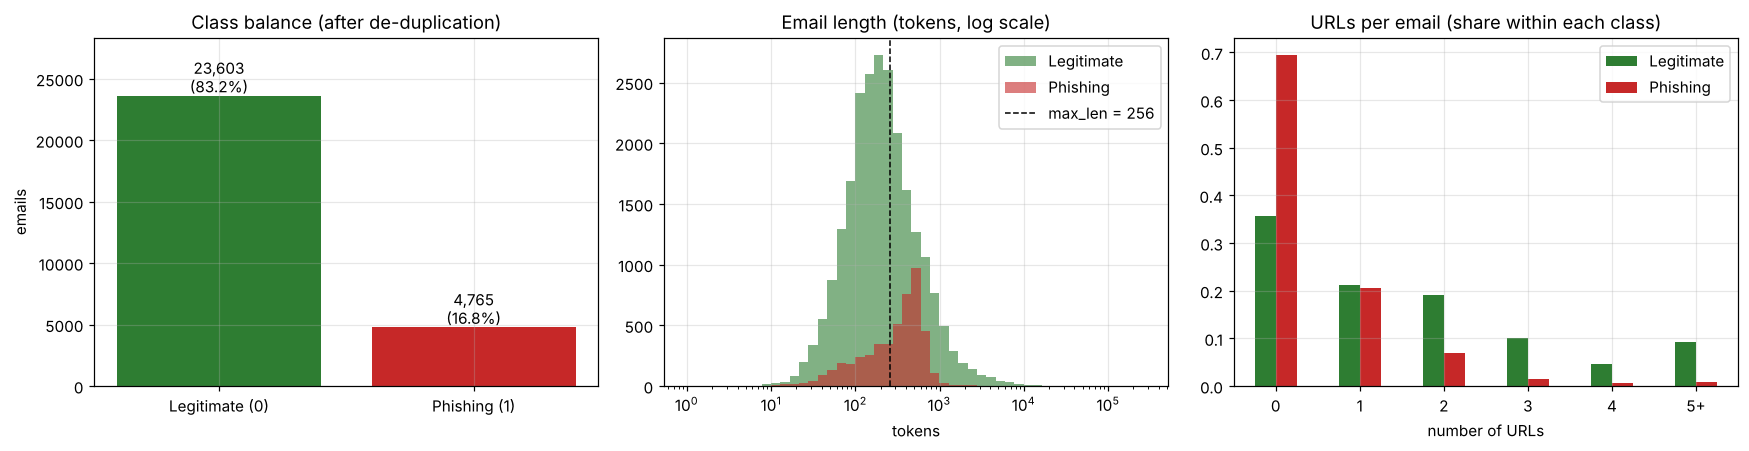

Token length percentiles (50/75/90/95): [ 212.  416.  691. 1009.]
Share of emails fully covered by max_len=256: 57.6%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

counts = df["label"].value_counts().sort_index()
axes[0].bar(["Legitimate (0)", "Phishing (1)"], counts.values, color=["#2e7d32", "#c62828"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Class balance (after de-duplication)"); axes[0].set_ylabel("emails")
axes[0].set_ylim(0, counts.max() * 1.2)

bins = np.logspace(0, np.log10(df["n_tokens"].max() + 1), 50)
for lab, name, col in [(0, "Legitimate", "#2e7d32"), (1, "Phishing", "#c62828")]:
    axes[1].hist(df.loc[df.label == lab, "n_tokens"], bins=bins, alpha=0.6, label=name, color=col)
axes[1].set_xscale("log"); axes[1].axvline(256, ls="--", c="k", lw=1, label="max_len = 256")
axes[1].set_title("Email length (tokens, log scale)"); axes[1].set_xlabel("tokens"); axes[1].legend()

url_tab = df.assign(urls=df["n_urls"].clip(upper=5)).groupby(["urls", "label"]).size().unstack(fill_value=0)
url_tab = url_tab / url_tab.sum()
url_tab.plot.bar(ax=axes[2], color=["#2e7d32", "#c62828"], rot=0)
axes[2].set_xticklabels([str(i) if i < 5 else "5+" for i in url_tab.index])
axes[2].set_title("URLs per email (share within each class)"); axes[2].set_xlabel("number of URLs")
axes[2].legend(["Legitimate", "Phishing"])
plt.tight_layout(); savefig("eda_overview"); plt.show()

print("Token length percentiles (50/75/90/95):", np.percentile(df["n_tokens"], [50, 75, 90, 95]).round())
print(f"Share of emails fully covered by max_len=256: {(df['n_tokens'] <= 256).mean():.1%}")

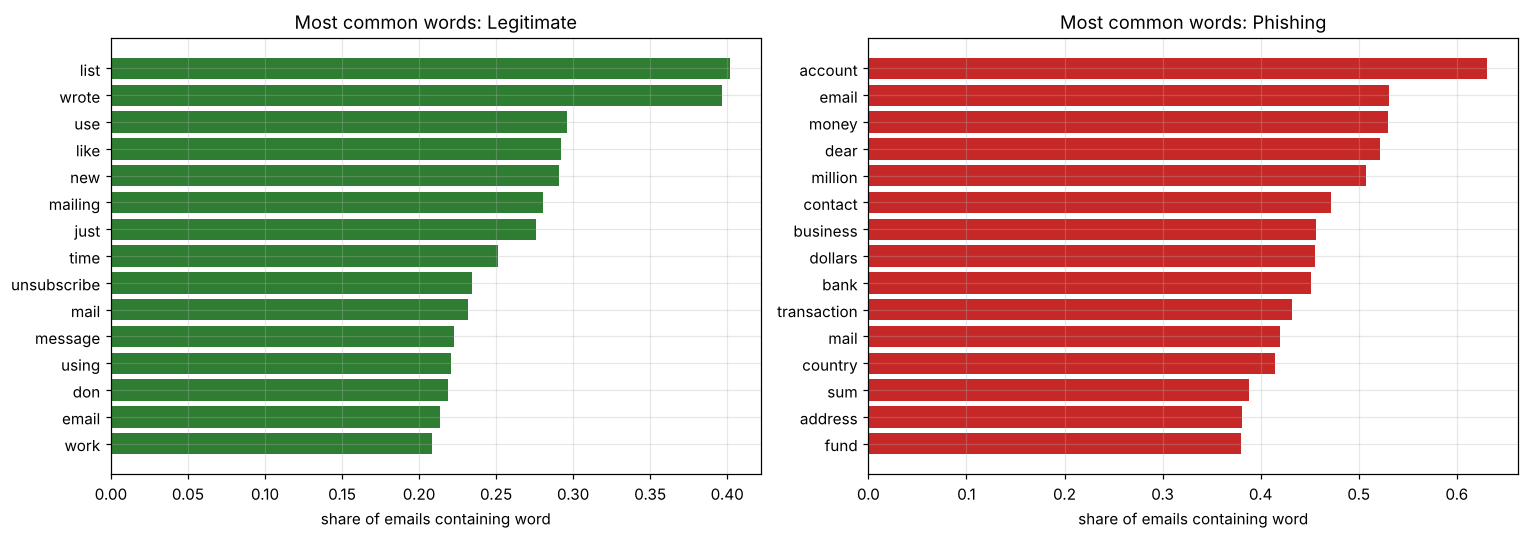

In [8]:
from collections import Counter
STOP = set(ENGLISH_STOP_WORDS) | {"numtoken", "urltoken", "emailtoken", "!", "?", "$", "%"}

def top_words(texts, n=15):
    c = Counter(w for t in texts for w in set(t.split()) if w not in STOP and len(w) > 2)
    return c.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, name, col in [(axes[0], 0, "Legitimate", "#2e7d32"), (axes[1], 1, "Phishing", "#c62828")]:
    words, freq = zip(*top_words(df.loc[df.label == lab, "text"]))
    ax.barh(words[::-1], np.array(freq[::-1]) / (df.label == lab).sum(), color=col)
    ax.set_title(f"Most common words: {name}"); ax.set_xlabel("share of emails containing word")
plt.tight_layout(); savefig("eda_top_words"); plt.show()

## 6. Train / validation / test split (rubric 2.2)

Stratified **70 / 15 / 15** split with a fixed seed, so the class ratio matches in each set and the split can be reproduced.

* **Train:** fits the model weights and builds the vocabulary.
* **Validation:** checked after every epoch for early stopping, model selection and choosing the decision threshold.
* **Test:** used **once**, at the end, for the final reported results.

In [9]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

split_summary = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "emails": [len(train_df), len(val_df), len(test_df)],
    "share": [len(train_df)/len(df), len(val_df)/len(df), len(test_df)/len(df)],
    "phishing": [d.label.sum() for d in (train_df, val_df, test_df)],
    "phishing_rate": [d.label.mean() for d in (train_df, val_df, test_df)],
})
display(split_summary.style.format({"share": "{:.1%}", "phishing_rate": "{:.1%}", "emails": "{:,}", "phishing": "{:,}"}))
assert not set(train_df.text) & set(test_df.text), "leakage: identical email in train and test"
assert not set(train_df.text) & set(val_df.text), "leakage: identical email in train and validation"
print("No identical emails shared between splits.")

,set,emails,share,phishing,phishing_rate
0,train,"19,857",70.0%,"3,335",16.8%
1,validation,"4,255",15.0%,715,16.8%
2,test,"4,256",15.0%,715,16.8%


No identical emails shared between splits.


## 7. Baseline: TF-IDF + Logistic Regression

A classical baseline sets a reference point, so we can show the deep model actually adds something. TF-IDF weights each word or two-word phrase by how distinctive it is. Logistic regression then learns one weight per feature. The baseline is fast, and the weights are directly interpretable (see Section 13).

In [10]:
def compute_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
    }

def best_f1_threshold(y_true, prob):
    """Pick the decision threshold that maximises F1 on the VALIDATION set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.argmax(f1[:-1])])

t0 = time.time()
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
    ("clf", LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced")),
])
baseline.fit(train_df.text, train_df.label)
print(f"Baseline trained in {time.time()-t0:.1f}s")

base_val_prob = baseline.predict_proba(val_df.text)[:, 1]
BASE_THRESHOLD = best_f1_threshold(val_df.label, base_val_prob)
base_test_prob = baseline.predict_proba(test_df.text)[:, 1]

display(pd.DataFrame({
    "validation": compute_metrics(val_df.label, base_val_prob, BASE_THRESHOLD),
    "test": compute_metrics(test_df.label, base_test_prob, BASE_THRESHOLD),
}).T.style.format("{:.4f}").set_caption(f"TF-IDF + LogReg (threshold {BASE_THRESHOLD:.3f}, tuned on validation)"))
joblib.dump(baseline, MODEL_DIR / "baseline_tfidf_logreg.joblib")

Baseline trained in 16.0s


,accuracy,precision,recall,f1,auc_roc,pr_auc
validation,0.9967,0.9944,0.9860,0.9902,0.9988,0.9967
test,0.9946,0.9929,0.9748,0.9838,0.9996,0.9987


['/home/claude/proj/models/baseline_tfidf_logreg.joblib']

## 8. Main model: Bidirectional LSTM (rubric 2.1)

**Architecture** (the full code is in the cell below):

| Layer | Details | Output shape |
|---|---|---|
| Input | token ids, truncated to `max_len = 256` (covers ~80% of emails in full) | (B, T) |
| Embedding | 25,000 × 100, learned from scratch, `padding_idx = 0` | (B, T, 100) |
| Dropout | p = 0.3 | |
| BiLSTM | 1 layer, 64 hidden units per direction, packed sequences so padding is ignored | (B, T, 128) |
| Pooling | masked **mean** + masked **max** over time, concatenated | (B, 256) |
| Dense + ReLU | 256 → 64 | (B, 64) |
| Dropout | p = 0.3 | |
| Output | 64 → 1 logit; **sigmoid** gives P(phishing) | (B,) |

* **Loss:** `BCEWithLogitsLoss` (sigmoid + binary cross-entropy).
* **Optimiser:** Adam, learning rate 1e-3, gradient clipping at 1.0.
* **Why a BiLSTM suits email text:**
  * Word order and context matter ("verify your account" vs "account verified").
  * The forward and backward passes let each word see both what came before and what comes after.
  * Max-pooling captures the single most suspicious phrase anywhere in the email, while mean-pooling captures the overall tone.

In [11]:
%%writefile ../phishing_core/model.py
"""BiLSTM phishing classifier + an inference wrapper used by the notebook and the API.

This file is generated from notebooks/02_model_training.ipynb (%%writefile cell).
Edit it there and re-run the notebook so the notebook and the API stay in sync.
"""
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .text import Vocab, clean_text, count_urls, tokenize


class BiLSTMClassifier(nn.Module):
    """Embedding -> BiLSTM -> masked mean+max pooling -> MLP head -> 1 logit.

    Output is a single logit; sigmoid(logit) = P(phishing). Trained with
    BCEWithLogitsLoss (sigmoid + binary cross-entropy in one numerically stable op).
    """

    def __init__(self, vocab_size, emb_dim=100, hidden_dim=64, num_layers=1,
                 dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 2 * 2, 64),  # (fwd+bwd) x (mean+max)
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x, lengths):
        emb = self.emb_dropout(self.embedding(x))                       # (B, T, E)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True,
                                     total_length=x.size(1))            # (B, T, 2H)
        mask = (torch.arange(x.size(1), device=x.device)[None, :]
                < lengths[:, None].to(x.device)).unsqueeze(-1)          # (B, T, 1)
        mean_pool = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        max_pool = out.masked_fill(~mask, -1e9).max(1).values
        return self.head(torch.cat([mean_pool, max_pool], dim=1)).squeeze(1)


def collate_ids(seqs, pad_idx=0):
    """Pad a list of id-lists into a batch tensor plus a lengths tensor."""
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
    batch = torch.full((len(seqs), int(lengths.max())), pad_idx, dtype=torch.long)
    for i, s in enumerate(seqs):
        batch[i, : len(s)] = torch.tensor(s, dtype=torch.long)
    return batch, lengths


class PhishingDetector:
    """Loads the saved BiLSTM (and optional baseline) and serves predictions."""

    def __init__(self, model_dir):
        model_dir = Path(model_dir)
        self.config = json.loads((model_dir / "config.json").read_text(encoding="utf-8"))
        self.vocab = Vocab.load(model_dir / "vocab.json")
        self.max_len = self.config["max_len"]
        self.threshold = float(self.config.get("threshold", 0.5))
        self.device = torch.device("cpu")
        self.model = BiLSTMClassifier(len(self.vocab), **self.config["model_params"])
        state = torch.load(model_dir / "bilstm.pt", map_location=self.device)
        self.model.load_state_dict(state)
        self.model.eval()
        self.baseline = None
        baseline_path = model_dir / "baseline_tfidf_logreg.joblib"
        if baseline_path.exists():
            import joblib
            self.baseline = joblib.load(baseline_path)
            self.baseline_threshold = float(self.config.get("baseline_threshold", 0.5))

    # ---------- BiLSTM ----------
    @torch.no_grad()
    def _logits_from_tokens(self, token_lists, batch_size=256):
        logits = []
        for i in range(0, len(token_lists), batch_size):
            ids = [self.vocab.encode(t, self.max_len) for t in token_lists[i:i + batch_size]]
            x, lengths = collate_ids(ids)
            logits.append(self.model(x, lengths).numpy())
        return np.concatenate(logits) if logits else np.array([])

    def _proba_from_tokens(self, token_lists, batch_size=256):
        return 1.0 / (1.0 + np.exp(-self._logits_from_tokens(token_lists, batch_size)))

    def predict_proba(self, texts):
        """texts: list of already-cleaned strings -> P(phishing) for each."""
        return self._proba_from_tokens([tokenize(t) for t in texts])

    def explain(self, text, top_k=10):
        """Occlusion (leave-one-word-out) explanation.

        For each distinct word, remove every occurrence and measure how much the
        model's log-odds of phishing change. Log-odds are used instead of the raw
        probability because a probability of 0.9999 hardly moves when one word is
        removed (sigmoid saturation), while the log-odds still show the effect.
        Positive weight = the word pushes the email towards phishing.
        """
        tokens = tokenize(text)[: self.max_len]
        if not tokens:
            return []
        base = float(self._logits_from_tokens([tokens])[0])
        words = list(dict.fromkeys(tokens))[:200]
        variants = [[t for t in tokens if t != w] or ["<unk>"] for w in words]
        weights = base - self._logits_from_tokens(variants)
        order = np.argsort(-np.abs(weights))[:top_k]
        return [{"token": words[i], "weight": round(float(weights[i]), 4)} for i in order]

    # ---------- public API ----------
    def analyse(self, subject, body, model="bilstm", explain=True, top_k=10):
        text = clean_text(subject, body)
        if model == "baseline":
            if self.baseline is None:
                raise ValueError("Baseline model not available")
            prob = float(self.baseline.predict_proba([text])[0, 1])
            threshold = self.baseline_threshold
            tokens = self._baseline_explain(text, top_k) if explain else []
        else:
            prob = float(self.predict_proba([text])[0])
            threshold = self.threshold
            tokens = self.explain(text, top_k) if explain else []
        return {
            "label": "phishing" if prob >= threshold else "legitimate",
            "probability": round(prob, 4),
            "threshold": round(threshold, 4),
            "model": model,
            "top_tokens": tokens,
            "indicators": {
                "url_count": count_urls(f"{subject or ''} {body or ''}"),
                "word_count": len(tokenize(text)),
                "exclamation_marks": text.count("!"),
            },
        }

    def _baseline_explain(self, text, top_k=10):
        """For TF-IDF + LogReg: contribution = tfidf value x coefficient."""
        vec = self.baseline.named_steps["tfidf"]
        clf = self.baseline.named_steps["clf"]
        row = vec.transform([text]).tocoo()
        names = vec.get_feature_names_out()
        contrib = [(names[j], float(v * clf.coef_[0][j])) for j, v in zip(row.col, row.data)]
        contrib.sort(key=lambda t: -abs(t[1]))
        return [{"token": w, "weight": round(c, 4)} for w, c in contrib[:top_k]]

Overwriting ../phishing_core/model.py


In [12]:
import phishing_core.model as pmodel
importlib.reload(pmodel)
from phishing_core.model import BiLSTMClassifier, collate_ids, PhishingDetector

CONFIG = {
    "max_len": 256, "vocab_size": 25000, "min_freq": 2,
    "model_params": {"emb_dim": 100, "hidden_dim": 64, "num_layers": 1, "dropout": 0.3},
    "batch_size": 64, "lr": 1e-3, "max_epochs": 15, "patience": 3, "min_delta": 1e-4, "grad_clip": 1.0,
}

vocab = Vocab.build((t.split() for t in train_df.text), CONFIG["vocab_size"], CONFIG["min_freq"])
encode = lambda texts: [vocab.encode(t.split(), CONFIG["max_len"]) for t in texts]
X_train, X_val, X_test = encode(train_df.text), encode(val_df.text), encode(test_df.text)
y_train, y_val, y_test = (d.label.values.astype(np.float32) for d in (train_df, val_df, test_df))
unk_rate = np.mean([np.mean(np.array(s) == vocab.unk_idx) for s in X_val])
print(f"Vocabulary: {len(vocab):,} tokens | unknown-token rate on validation: {unk_rate:.1%}")

model = BiLSTMClassifier(len(vocab), **CONFIG["model_params"]).to(DEVICE)
print(model)
layer_params = pd.DataFrame([(n, tuple(p.shape), p.numel()) for n, p in model.named_parameters()],
                            columns=["parameter", "shape", "count"])
display(layer_params)
print(f"Total trainable parameters: {layer_params['count'].sum():,}")

Vocabulary: 25,000 tokens | unknown-token rate on validation: 3.5%


BiLSTMClassifier(
  (embedding): Embedding(25000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


,parameter,shape,count
0,embedding.weight,"(25000, 100)",2500000
1,lstm.weight_ih_l0,"(256, 100)",25600
2,lstm.weight_hh_l0,"(256, 64)",16384
3,lstm.bias_ih_l0,"(256,)",256
4,lstm.bias_hh_l0,"(256,)",256
5,lstm.weight_ih_l0_reverse,"(256, 100)",25600
6,lstm.weight_hh_l0_reverse,"(256, 64)",16384
7,lstm.bias_ih_l0_reverse,"(256,)",256
8,lstm.bias_hh_l0_reverse,"(256,)",256
9,head.0.weight,"(64, 256)",16384


Total trainable parameters: 2,601,505


## 9. Training loop with per-epoch metric logging (2.3) and early stopping (2.6)

* **Length bucketing:** emails of similar length are batched together, so little time is wasted on padding. This keeps CPU training practical.
* **Per-epoch logging:** after **every epoch** we log train loss and accuracy, plus validation loss, accuracy, precision, recall, F1, AUC-ROC and PR-AUC. Each epoch's values are printed and stored in `metrics_log`, which is saved to CSV.
* **Class weighting:** phishing emails are the minority, so the loss gives each phishing email a larger weight (`pos_weight` = legitimate ÷ phishing in the training set). Without this, the model could score well by mostly predicting "legitimate".
* **Early stopping:** if validation loss does not improve by at least `min_delta` for `patience = 3` epochs in a row, training stops. The weights from the best epoch are restored, so the model we keep is the one before overfitting began.

In [13]:
def bucket_batches(seqs, batch_size, shuffle, rng):
    """Group similar-length sequences into batches (less padding = faster training)."""
    order = np.argsort([len(s) for s in seqs], kind="stable")
    batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return batches

@torch.no_grad()
def predict(model, seqs, batch_size=256):
    model.eval()
    out = np.zeros(len(seqs), dtype=np.float32)
    for idx in bucket_batches(seqs, batch_size, False, None):
        x, lengths = collate_ids([seqs[i] for i in idx])
        out[idx] = torch.sigmoid(model(x.to(DEVICE), lengths)).cpu().numpy()
    return out

class EarlyStopping:
    """Stop when the monitored metric has not improved for `patience` epochs."""
    def __init__(self, patience=3, min_delta=1e-4, mode="min"):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.best, self.best_epoch, self.counter, self.best_state = None, 0, 0, None
        self.triggered = False

    def step(self, value, model, epoch):
        improved = (self.best is None or
                    (value < self.best - self.min_delta if self.mode == "min" else value > self.best + self.min_delta))
        if improved:
            self.best, self.best_epoch, self.counter = value, epoch, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            self.triggered = self.counter >= self.patience
        return improved

torch.manual_seed(SEED)
model = BiLSTMClassifier(len(vocab), **CONFIG["model_params"]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["lr"])
# Class weighting: there are far fewer phishing than legitimate emails, so each phishing email counts more.
pos_weight = torch.tensor([(y_train == 0).sum() / max((y_train == 1).sum(), 1)], device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"pos_weight = {pos_weight.item():.2f}  (legitimate : phishing ratio in the training set)")
stopper = EarlyStopping(CONFIG["patience"], CONFIG["min_delta"], mode="min")
rng = np.random.default_rng(SEED)

metrics_log, batch_losses = [], []
header = (f"{'epoch':>5} | {'train_loss':>10} {'train_acc':>9} | {'val_loss':>8} {'val_acc':>7} "
          f"{'val_prec':>8} {'val_rec':>7} {'val_f1':>6} {'val_auc':>7} {'val_prauc':>9} | {'time':>5} | note")
print(header); print("-" * len(header))

for epoch in range(1, CONFIG["max_epochs"] + 1):
    t0 = time.time(); model.train()
    run_loss, run_correct, seen = 0.0, 0, 0
    for idx in bucket_batches(X_train, CONFIG["batch_size"], True, rng):
        x, lengths = collate_ids([X_train[i] for i in idx])
        y = torch.tensor(y_train[idx], device=DEVICE)
        logits = model(x.to(DEVICE), lengths)
        loss = criterion(logits, y)
        optimizer.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
        optimizer.step()
        batch_losses.append(loss.item())
        run_loss += loss.item() * len(idx); seen += len(idx)
        run_correct += ((logits.detach() > 0).float() == y).sum().item()

    val_prob = predict(model, X_val)
    row = {"epoch": epoch, "train_loss": run_loss / seen, "train_accuracy": run_correct / seen,
           "val_loss": log_loss(y_val, np.clip(val_prob, 1e-7, 1 - 1e-7))}
    row.update({f"val_{k}": v for k, v in compute_metrics(y_val, val_prob).items()})
    row["epoch_time_s"] = time.time() - t0
    improved = stopper.step(row["val_loss"], model, epoch)
    row["best_so_far"] = improved
    metrics_log.append(row)

    note = "* new best (saved)" if improved else f"no improvement {stopper.counter}/{CONFIG['patience']}"
    print(f"{epoch:>5} | {row['train_loss']:>10.4f} {row['train_accuracy']:>9.4f} | {row['val_loss']:>8.4f} "
          f"{row['val_accuracy']:>7.4f} {row['val_precision']:>8.4f} {row['val_recall']:>7.4f} {row['val_f1']:>6.4f} "
          f"{row['val_auc_roc']:>7.4f} {row['val_pr_auc']:>9.4f} | {row['epoch_time_s']:>4.0f}s | {note}")
    if stopper.triggered:
        print(f"\nEARLY STOPPING triggered at epoch {epoch}: validation loss did not improve for "
              f"{CONFIG['patience']} consecutive epochs.")
        break
else:
    print(f"\nReached max_epochs = {CONFIG['max_epochs']} without triggering early stopping.")

model.load_state_dict(stopper.best_state)
print(f"Restored best weights from epoch {stopper.best_epoch} (val_loss = {stopper.best:.4f}).")

metrics_log = pd.DataFrame(metrics_log)
metrics_log.to_csv(RESULTS_DIR / "metrics_log.csv", index=False)
display(metrics_log.style.format(precision=4).highlight_min(subset=["val_loss"], color="#c8e6c9"))

pos_weight = 4.95  (legitimate : phishing ratio in the training set)
epoch | train_loss train_acc | val_loss val_acc val_prec val_rec val_f1 val_auc val_prauc |  time | note
--------------------------------------------------------------------------------------------------------


    1 |     0.3625    0.9331 |   0.0625  0.9812   0.9150  0.9790 0.9459  0.9975    0.9913 |   96s | * new best (saved)


    2 |     0.0756    0.9879 |   0.0376  0.9899   0.9706  0.9692 0.9699  0.9978    0.9935 |   90s | * new best (saved)


    3 |     0.0464    0.9919 |   0.0277  0.9922   0.9736  0.9804 0.9770  0.9985    0.9959 |   93s | * new best (saved)


    4 |     0.0317    0.9954 |   0.0269  0.9932   0.9751  0.9846 0.9798  0.9986    0.9964 |   89s | * new best (saved)


    5 |     0.0210    0.9971 |   0.0297  0.9934   0.9872  0.9734 0.9803  0.9984    0.9960 |   91s | no improvement 1/3


    6 |     0.0160    0.9974 |   0.0341  0.9937   0.9738  0.9888 0.9813  0.9984    0.9962 |   91s | no improvement 2/3


    7 |     0.0115    0.9982 |   0.0374  0.9944   0.9792  0.9874 0.9833  0.9982    0.9963 |   92s | no improvement 3/3

EARLY STOPPING triggered at epoch 7: validation loss did not improve for 3 consecutive epochs.
Restored best weights from epoch 4 (val_loss = 0.0269).


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_auc_roc,val_pr_auc,epoch_time_s,best_so_far
0,1,0.3625,0.9331,0.0625,0.9812,0.9150,0.9790,0.9459,0.9975,0.9913,95.6817,True
1,2,0.0756,0.9879,0.0376,0.9899,0.9706,0.9692,0.9699,0.9978,0.9935,89.7293,True
2,3,0.0464,0.9919,0.0277,0.9922,0.9736,0.9804,0.9770,0.9985,0.9959,92.8897,True
3,4,0.0317,0.9954,0.0269,0.9932,0.9751,0.9846,0.9798,0.9986,0.9964,89.3084,True
4,5,0.0210,0.9971,0.0297,0.9934,0.9872,0.9734,0.9803,0.9984,0.9960,90.8494,False
5,6,0.0160,0.9974,0.0341,0.9937,0.9738,0.9888,0.9813,0.9984,0.9962,90.8830,False
6,7,0.0115,0.9982,0.0374,0.9944,0.9792,0.9874,0.9833,0.9982,0.9963,92.3460,False


## 10. Metric graphs (rubric 2.4)

### 10.1 Training curves (per epoch)

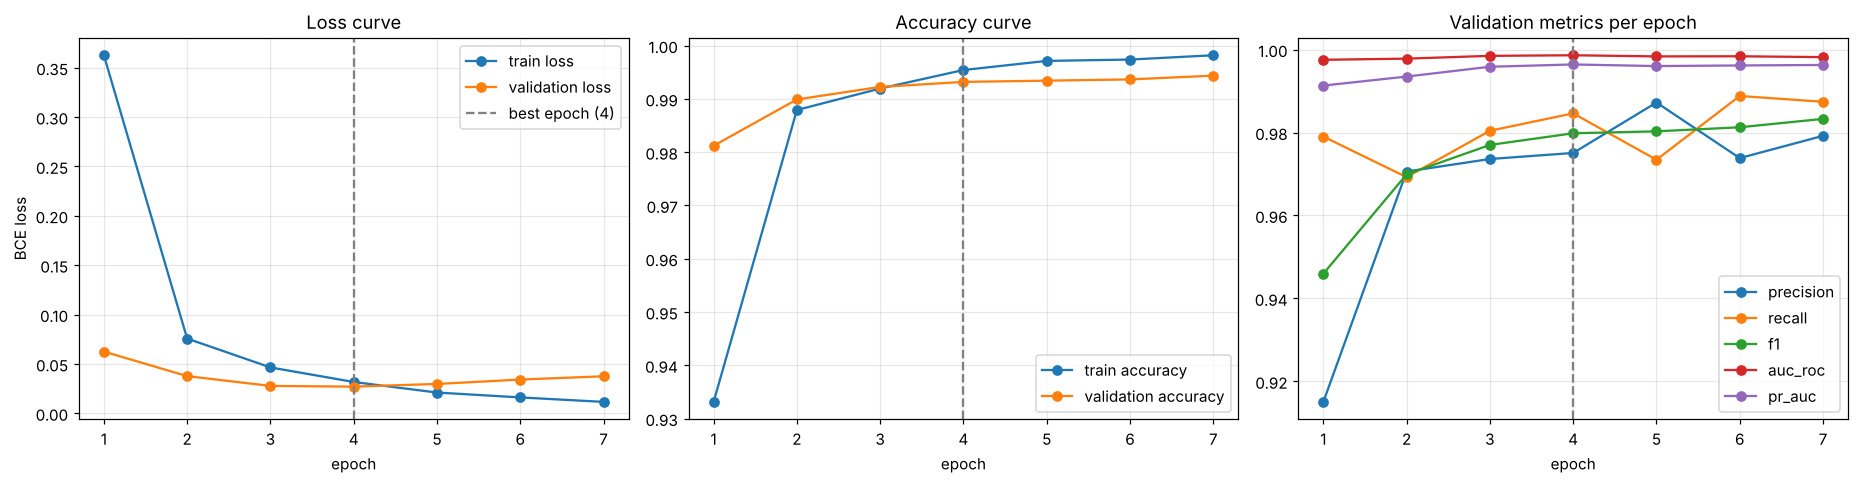

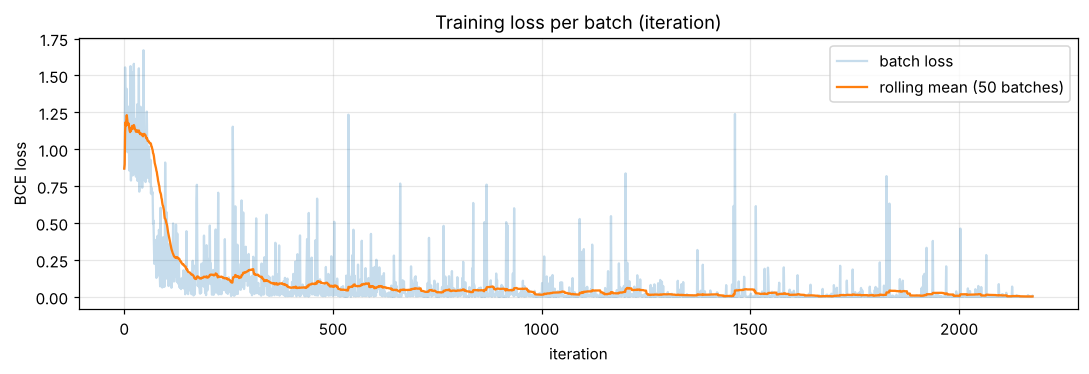

In [14]:
ep, best = metrics_log["epoch"], stopper.best_epoch
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(ep, metrics_log.train_loss, "o-", label="train loss")
axes[0].plot(ep, metrics_log.val_loss, "o-", label="validation loss")
axes[0].axvline(best, ls="--", c="grey", label=f"best epoch ({best})")
axes[0].set_title("Loss curve"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()

axes[1].plot(ep, metrics_log.train_accuracy, "o-", label="train accuracy")
axes[1].plot(ep, metrics_log.val_accuracy, "o-", label="validation accuracy")
axes[1].axvline(best, ls="--", c="grey")
axes[1].set_title("Accuracy curve"); axes[1].set_xlabel("epoch"); axes[1].legend()

for m in ["precision", "recall", "f1", "auc_roc", "pr_auc"]:
    axes[2].plot(ep, metrics_log[f"val_{m}"], "o-", label=m)
axes[2].axvline(best, ls="--", c="grey")
axes[2].set_title("Validation metrics per epoch"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.tight_layout(); savefig("training_curves"); plt.show()

plt.figure(figsize=(10, 3.5))
s = pd.Series(batch_losses)
plt.plot(s, alpha=0.25, label="batch loss")
plt.plot(s.rolling(50, min_periods=1).mean(), label="rolling mean (50 batches)")
plt.title("Training loss per batch (iteration)"); plt.xlabel("iteration"); plt.ylabel("BCE loss"); plt.legend()
plt.tight_layout(); savefig("batch_loss"); plt.show()

### 10.2 Final evaluation on the held-out test set

The decision threshold is chosen on the **validation** set to maximise F1, then applied unchanged to the test set. The test set plays no part in any decision.

In [15]:
val_prob = predict(model, X_val)
THRESHOLD = best_f1_threshold(y_val, val_prob)
test_prob = predict(model, X_test)

results = pd.DataFrame({
    "TF-IDF + LogReg (baseline)": compute_metrics(test_df.label, base_test_prob, BASE_THRESHOLD),
    "BiLSTM @ 0.5": compute_metrics(y_test, test_prob, 0.5),
    f"BiLSTM @ tuned {THRESHOLD:.3f}": compute_metrics(y_test, test_prob, THRESHOLD),
}).T
results.to_csv(RESULTS_DIR / "test_metrics.csv")
display(results.style.format("{:.4f}").highlight_max(color="#c8e6c9").set_caption("Test-set results"))

# Accuracy per source corpus: checks the model works on every kind of email, not just on average
by_src = (test_df.assign(pred=(test_prob >= THRESHOLD).astype(int))
          .groupby("source").apply(lambda g: pd.Series({
              "emails": len(g), "class": "phishing" if g.label.iloc[0] == 1 else "legitimate",
              "correct": (g.pred == g.label).mean()}), include_groups=False))
display(by_src.style.format({"correct": "{:.2%}", "emails": "{:,.0f}"}).set_caption("BiLSTM test accuracy per source"))

,accuracy,precision,recall,f1,auc_roc,pr_auc
TF-IDF + LogReg (baseline),0.9946,0.9929,0.9748,0.9838,0.9996,0.9987
BiLSTM @ 0.5,0.9941,0.9739,0.9916,0.9827,0.9996,0.9986
BiLSTM @ tuned 0.695,0.9955,0.9833,0.9902,0.9868,0.9996,0.9986


,emails,class,correct
source,,,
CEAS_08,"2,527",legitimate,99.64%
Ling,381,legitimate,99.21%
Nazario,213,phishing,98.59%
Nigerian_Fraud,502,phishing,99.20%
SpamAssasin,633,legitimate,100.00%


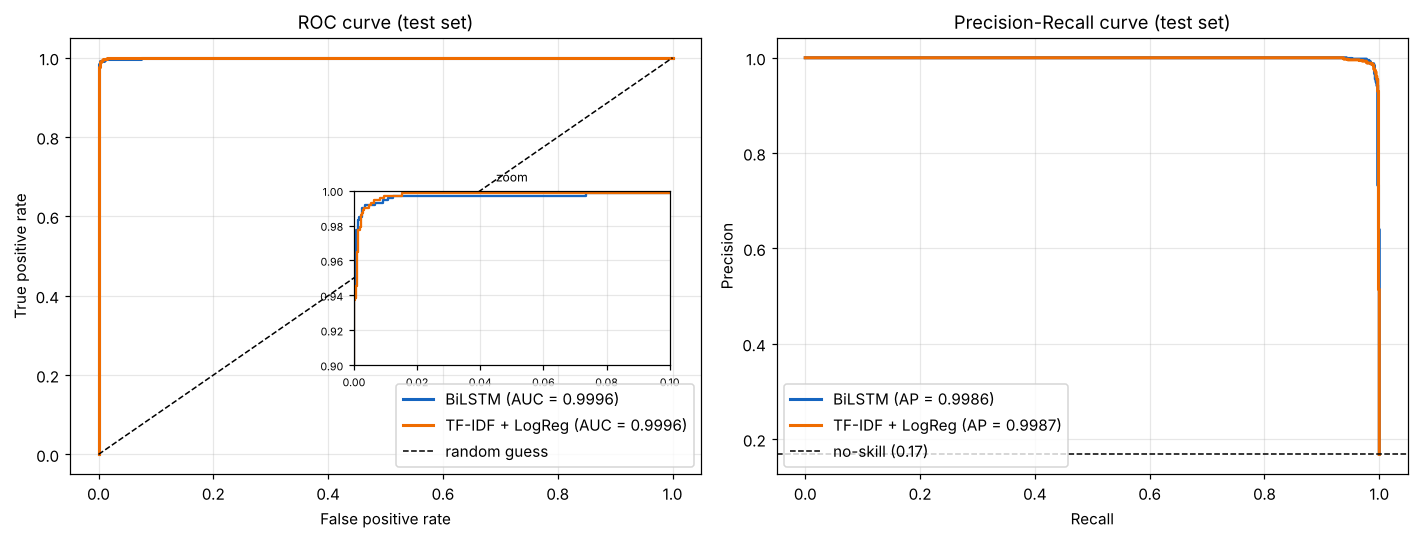

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob, col in [("BiLSTM", test_prob, "#1565c0"), ("TF-IDF + LogReg", base_test_prob, "#ef6c00")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=2, c=col, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.4f})")
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(r, p, lw=2, c=col, label=f"{name} (AP = {average_precision_score(y_test, prob):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), c="k", ls="--", lw=1, label=f"no-skill ({y_test.mean():.2f})")
axes[1].set(title="Precision-Recall curve (test set)", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "lower left")

# zoomed inset so the near-perfect top-left corner of the ROC is readable
ins = axes[0].inset_axes([0.45, 0.25, 0.5, 0.4])
for prob, col in [(test_prob, "#1565c0"), (base_test_prob, "#ef6c00")]:
    fpr, tpr, _ = roc_curve(y_test, prob); ins.plot(fpr, tpr, c=col)
ins.set_xlim(0, 0.1); ins.set_ylim(0.9, 1.0); ins.set_title("zoom", fontsize=8); ins.tick_params(labelsize=7)
plt.tight_layout(); savefig("roc_pr_curves"); plt.show()

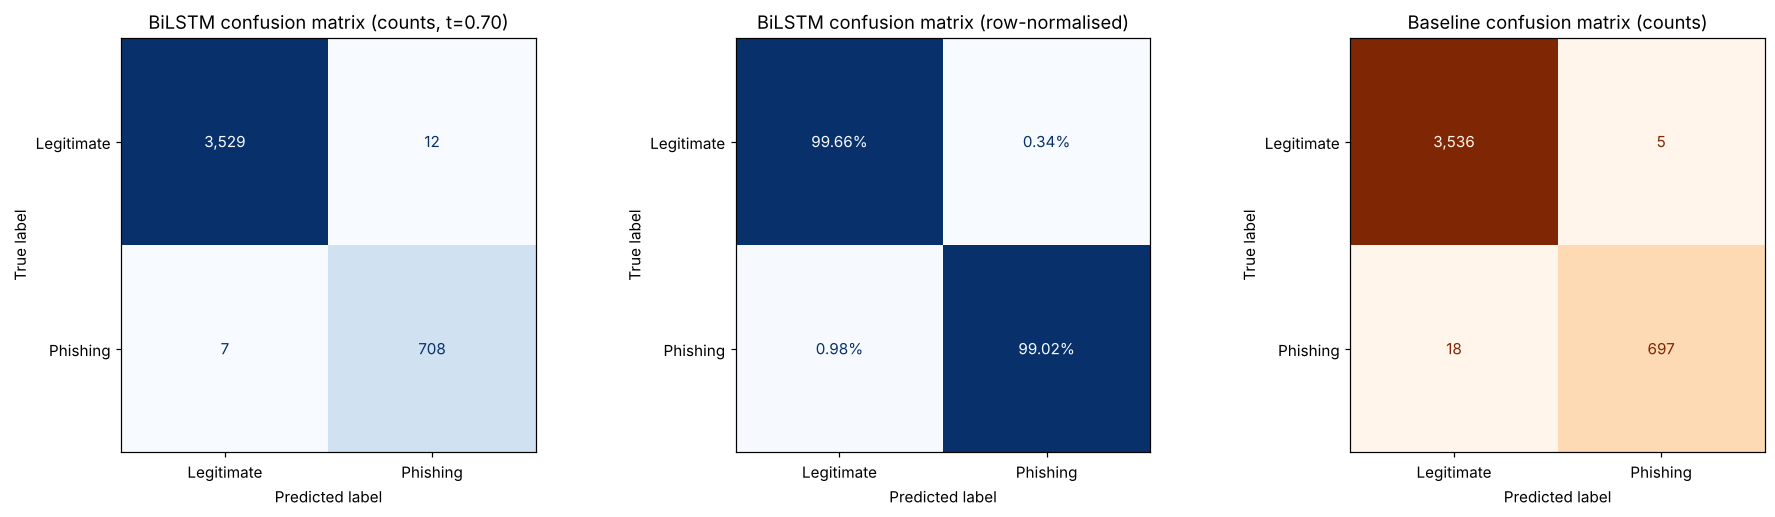

BiLSTM test: TP=708  TN=3,529  FP=12 (legit flagged)  FN=7 (phishing missed)
False positive rate = 0.34% | False negative rate = 0.98%


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = ["Legitimate", "Phishing"]
cm = confusion_matrix(y_test, (test_prob >= THRESHOLD).astype(int))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title(f"BiLSTM confusion matrix (counts, t={THRESHOLD:.2f})")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=labels).plot(
    ax=axes[1], cmap="Blues", values_format=".2%", colorbar=False)
axes[1].set_title("BiLSTM confusion matrix (row-normalised)")
cm_b = confusion_matrix(test_df.label, (base_test_prob >= BASE_THRESHOLD).astype(int))
ConfusionMatrixDisplay(cm_b, display_labels=labels).plot(ax=axes[2], cmap="Oranges", values_format=",d", colorbar=False)
axes[2].set_title("Baseline confusion matrix (counts)")
for ax in axes: ax.grid(False)
plt.tight_layout(); savefig("confusion_matrices"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"BiLSTM test: TP={tp:,}  TN={tn:,}  FP={fp:,} (legit flagged)  FN={fn:,} (phishing missed)")
print(f"False positive rate = {fp/(fp+tn):.2%} | False negative rate = {fn/(fn+tp):.2%}")

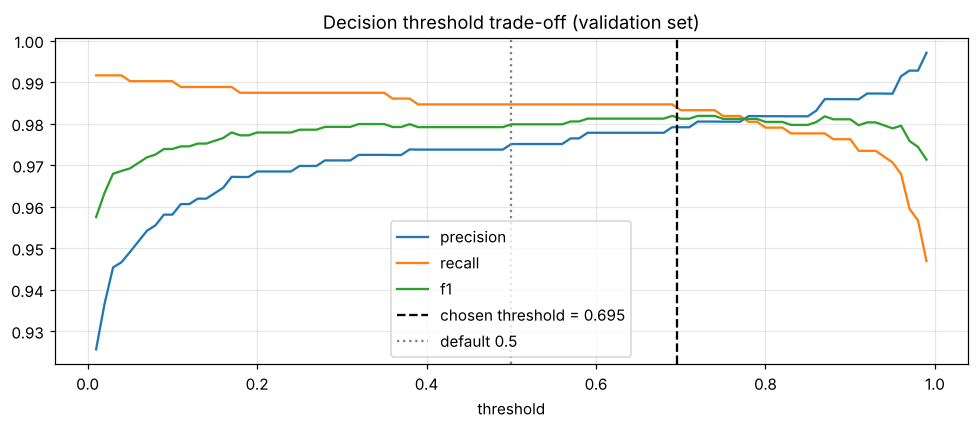

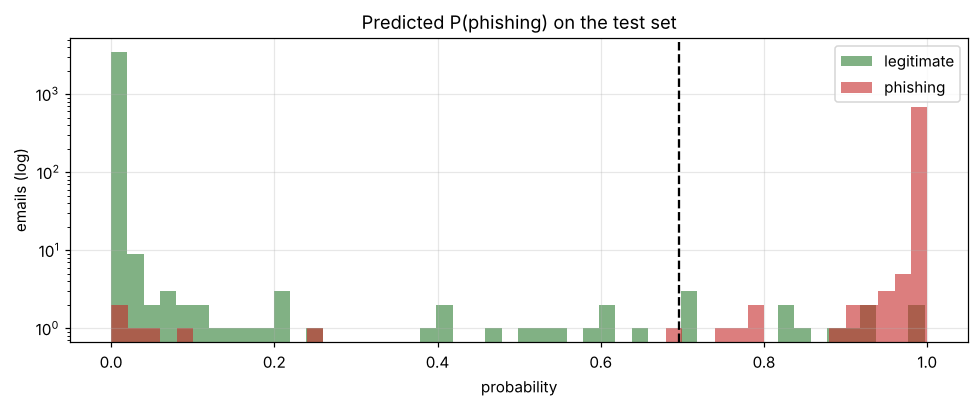

In [18]:
# Threshold trade-off: how precision / recall / F1 change as the cut-off moves (validation set)
ts = np.linspace(0.01, 0.99, 99)
curves = pd.DataFrame([{"t": t, **{k: v for k, v in compute_metrics(y_val, val_prob, t).items()
                                   if k in ("precision", "recall", "f1")}} for t in ts])
plt.figure(figsize=(9, 4))
for m in ["precision", "recall", "f1"]:
    plt.plot(curves.t, curves[m], label=m)
plt.axvline(THRESHOLD, c="k", ls="--", label=f"chosen threshold = {THRESHOLD:.3f}")
plt.axvline(0.5, c="grey", ls=":", label="default 0.5")
plt.title("Decision threshold trade-off (validation set)"); plt.xlabel("threshold"); plt.legend()
plt.tight_layout(); savefig("threshold_tradeoff"); plt.show()

plt.figure(figsize=(9, 3.8))
plt.hist(test_prob[y_test == 0], bins=50, alpha=0.6, color="#2e7d32", label="legitimate")
plt.hist(test_prob[y_test == 1], bins=50, alpha=0.6, color="#c62828", label="phishing")
plt.axvline(THRESHOLD, c="k", ls="--"); plt.yscale("log")
plt.title("Predicted P(phishing) on the test set"); plt.xlabel("probability"); plt.ylabel("emails (log)")
plt.legend(); plt.tight_layout(); savefig("probability_distribution"); plt.show()

## 11. Save the model for the API and desktop app

Saved to `models/`:
* `bilstm.pt`: the weights
* `vocab.json`: the vocabulary
* `config.json`: hyper-parameters, tuned thresholds and test metrics
* `baseline_tfidf_logreg.joblib`: the baseline model

The saved files are then reloaded through `PhishingDetector`, the same class the API uses, to confirm they produce identical predictions.

In [19]:
torch.save(model.state_dict(), MODEL_DIR / "bilstm.pt")
vocab.save(MODEL_DIR / "vocab.json")
saved_config = {
    "max_len": CONFIG["max_len"], "model_params": CONFIG["model_params"],
    "threshold": THRESHOLD, "baseline_threshold": BASE_THRESHOLD,
    "best_epoch": int(stopper.best_epoch), "epochs_run": int(len(metrics_log)),
    "trained_on": sorted(raw["source"].unique().tolist()),
    "train_size": len(train_df), "val_size": len(val_df), "test_size": len(test_df),
    "test_metrics": {k: round(float(v), 4) for k, v in compute_metrics(y_test, test_prob, THRESHOLD).items()},
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
}
(MODEL_DIR / "config.json").write_text(json.dumps(saved_config, indent=2))

detector = PhishingDetector(MODEL_DIR)
reloaded = detector.predict_proba(test_df.text.tolist()[:500])
assert np.allclose(reloaded, test_prob[:500], atol=1e-5), "saved model gives different predictions!"
print("Saved model reloads correctly:", [p.name for p in sorted(MODEL_DIR.iterdir())])
print(json.dumps(saved_config, indent=2))

Saved model reloads correctly: ['baseline_tfidf_logreg.joblib', 'bilstm.pt', 'config.json', 'vocab.json']
{
  "max_len": 256,
  "model_params": {
    "emb_dim": 100,
    "hidden_dim": 64,
    "num_layers": 1,
    "dropout": 0.3
  },
  "threshold": 0.6954349875450134,
  "baseline_threshold": 0.5980538740069697,
  "best_epoch": 4,
  "epochs_run": 7,
  "trained_on": [
    "CEAS_08",
    "Ling",
    "Nazario",
    "Nigerian_Fraud",
    "SpamAssasin"
  ],
  "train_size": 19857,
  "val_size": 4255,
  "test_size": 4256,
  "test_metrics": {
    "accuracy": 0.9955,
    "precision": 0.9833,
    "recall": 0.9902,
    "f1": 0.9868,
    "auc_roc": 0.9996,
    "pr_auc": 0.9986
  },
  "trained_at": "2026-10-17 15:05"
}


## 12. Error analysis

Here we look at the emails the model got **wrong**, with the most confident mistakes first. These cases show the model's limits and feed into the theory discussion (Section 3.3).

In [20]:
err = test_df.assign(prob=test_prob, pred=(test_prob >= THRESHOLD).astype(int))
show = lambda d: d[["subject", "prob"]].assign(body_start=d["body"].astype(str).str[:150].str.replace(r"\s+", " ", regex=True))
fp_df = err[(err.pred == 1) & (err.label == 0)].sort_values("prob", ascending=False)
fn_df = err[(err.pred == 0) & (err.label == 1)].sort_values("prob")
print(f"False positives (legitimate flagged as phishing): {len(fp_df)}")
display(show(fp_df.head(8)))
print(f"False negatives (phishing that got through): {len(fn_df)}")
display(show(fn_df.head(8)))

False positives (legitimate flagged as phishing): 12


,subject,prob,body_start
613,CONFIRMATION,0.996803,Due to settings on my computer I am unable to gain access the link for my confirmation. User name is NORDICBIKER. T...
309,$10 for a Few Minutes of Your Time,0.994870,"Dear TED, In our efforts to help serve you better, we're asking you to help us by completing our brief survey about ..."
4213,Salmon is good for your health. Please volunteer for this,0.932085,research project NOW! Sender: fedjda-irw-mvxfp@massey.ac.nz Precedence: bulk Reply-To: v.iqiifhwfng@massey.ac.nz Sal...
2781,Re: Guide,0.930757,"Hi, Tony! Here's the help you asked for: The Sandy Guide ----------------------------------- Welcome to my personal ..."
1790,Postfix sending mail to just other mail server,0.915230,"Dear all, I have my Debian+Postfix mail server, and it has to be an internal mail server. It shouldn't send mail to ..."
3658,[ydn-delicious] for: tag listing,0.894895,"I pulled up my only for:user tag, and though it said ""listing all 5 items"" there was only 1. Tim -- Tim Larson AMT2 ..."
1136,ii jornadas de linguistica aborigen,0.855870,"ii jornadas de linguistica aborigen buenos aires , argentina 15-18 de noviembre de 1994 facultad de filosofia y letr..."
3590,journees de rochebrune 99,0.835331,1st call for papers - - - - - - - - - - - - - - - - - - - - - journes de rochebrune 1999 : rencontres interdisciplin...


False negatives (phishing that got through): 7


,subject,prob,body_start
563,Turn your views into cash,0.000335,"Untitled Document Sit Back, Relax, and Get Paid for What You Think!! -Get paid to take online surveys $5 to $75 per ..."
117,Re: VdIAGRA,0.000642,"Hi, VdIAGRA for LESS http://www.oertionpidsadjinde.com struggle going on-apparently they are securing the bound man ..."
3882,Voice Mail Message 01-19-2022 - ( recipient ),0.031109,New Voice Message New Caller left a message(s) New voice messages left in your office mail directory From: 1-888-345...
2952,Email Quota,0.048864,All email users are to click on this link:http://inverbrujasltda.cl/rof/wp.html to upgrade their mail quota within 2...
2569,Re:{BN-5367029#},0.093342,Hello Kindly find attached for payment confirmation. Thanks Chan Wi
3080,NAPIMS,0.244801,"FROM THE DESK OF : GENERAL VICTOR MALU NATIONAL PETROLEUM INVESTMENTS MANAGEMENT SERVICES (NAPIMS), FEDERAL SECRETAR..."
445,business proposal,0.695300,"Kind Attn: CEO/ Manager Director Supply Quality China's EXCLUSIVE dimensions at Unbeatable Price. Dear Sir, We are p..."


## 13. Explainable AI (bonus, rubric 2.7)

Three complementary explanations:
1. **Global (baseline):** the logistic regression weights show which words push *any* email towards phishing or legitimate.
2. **Local, occlusion (BiLSTM):** remove each word from one specific email and measure how much the model's **log-odds** of phishing drop. Log-odds are used because a probability of 0.9999 barely changes when one word is removed. The desktop app uses this method to highlight words.
3. **Local, LIME (BiLSTM):** LIME fits a simple surrogate model around one email to explain the BiLSTM's decision for it (Ribeiro et al., 2016).

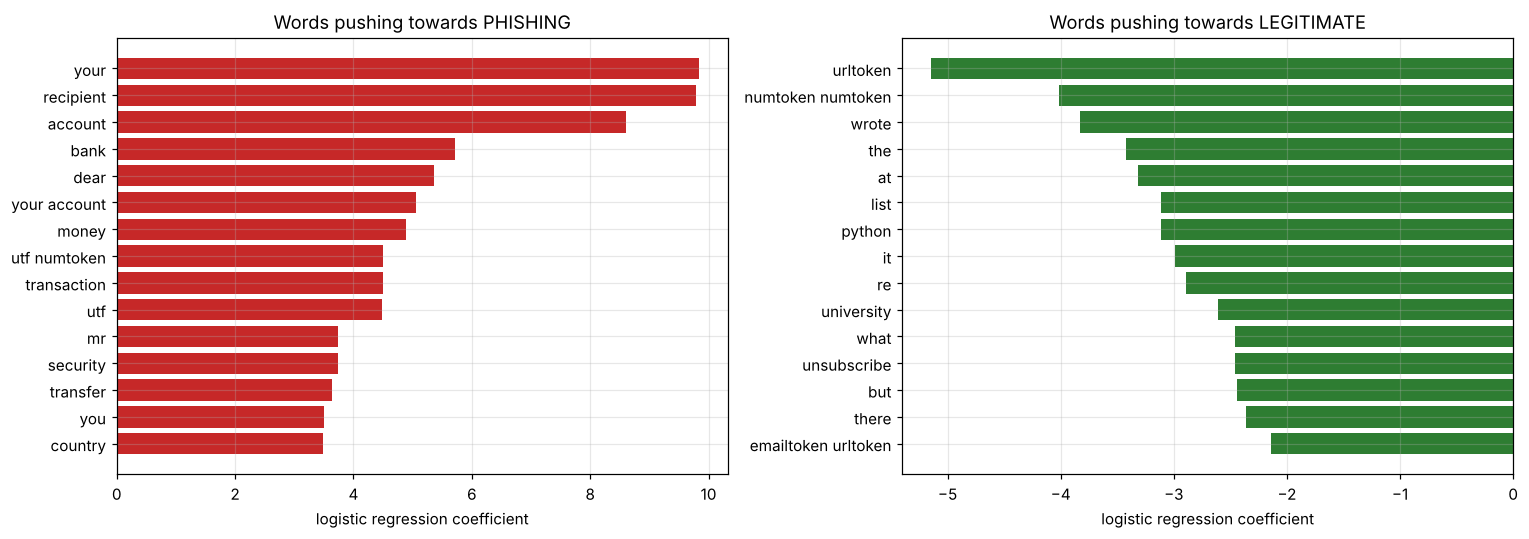

In [21]:
names = baseline.named_steps["tfidf"].get_feature_names_out()
coefs = baseline.named_steps["clf"].coef_[0]
top_pos, top_neg = np.argsort(coefs)[-15:], np.argsort(coefs)[:15]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(names[top_pos], coefs[top_pos], color="#c62828"); axes[0].set_title("Words pushing towards PHISHING")
axes[1].barh(names[top_neg][::-1], coefs[top_neg][::-1], color="#2e7d32"); axes[1].set_title("Words pushing towards LEGITIMATE")
for ax in axes: ax.set_xlabel("logistic regression coefficient")
plt.tight_layout(); savefig("xai_global_logreg"); plt.show()

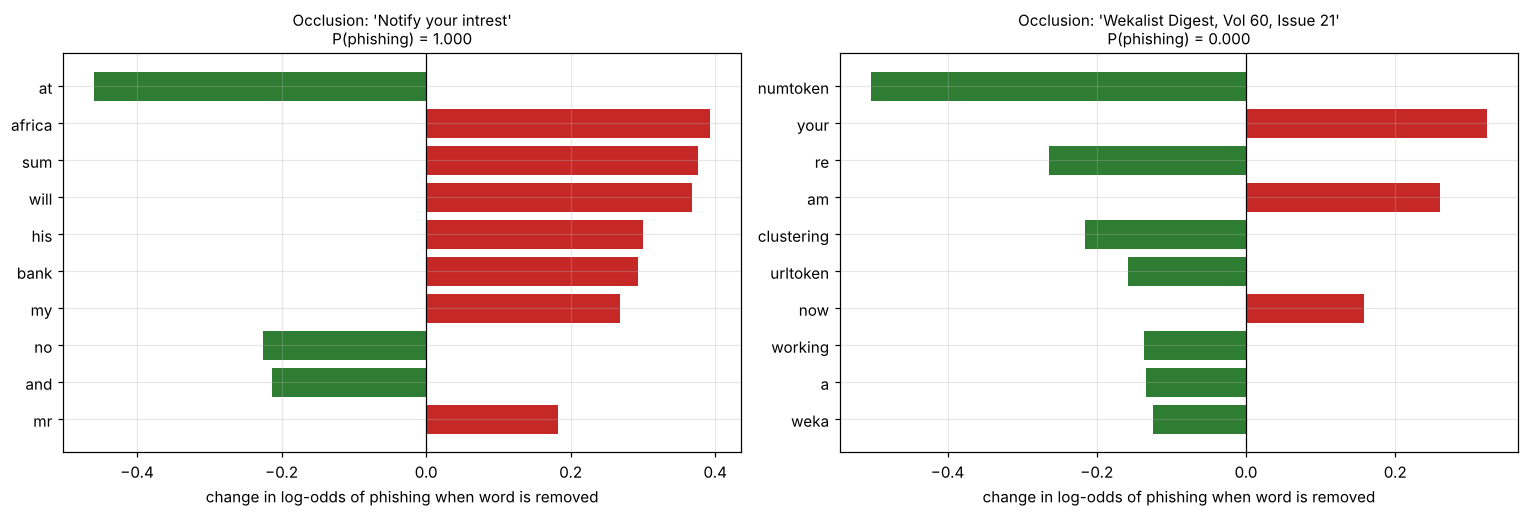

In [22]:
def plot_explanation(expl, title, ax):
    toks = [e["token"] for e in expl][::-1]; w = [e["weight"] for e in expl][::-1]
    ax.barh(toks, w, color=["#c62828" if v > 0 else "#2e7d32" for v in w])
    ax.axvline(0, c="k", lw=0.8); ax.set_title(title, fontsize=10)
    ax.set_xlabel("change in log-odds of phishing when word is removed")

ph_ex = test_df[(test_df.label == 1) & (test_prob > 0.95)].iloc[0]
lg_ex = test_df[(test_df.label == 0) & (test_prob < 0.05)].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, ex in zip(axes, [ph_ex, lg_ex]):
    r = detector.analyse(ex.subject, ex.body)
    plot_explanation(r["top_tokens"], f"Occlusion: '{str(ex.subject)[:45]}'\nP(phishing) = {r['probability']:.3f}", ax)
plt.tight_layout(); savefig("xai_occlusion"); plt.show()

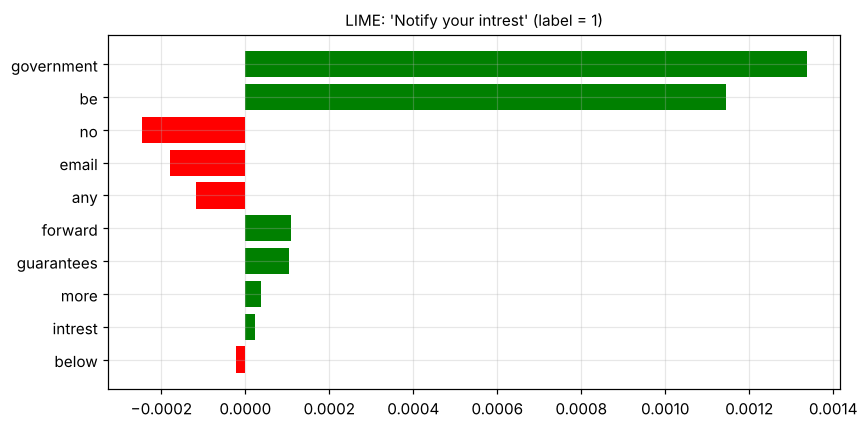

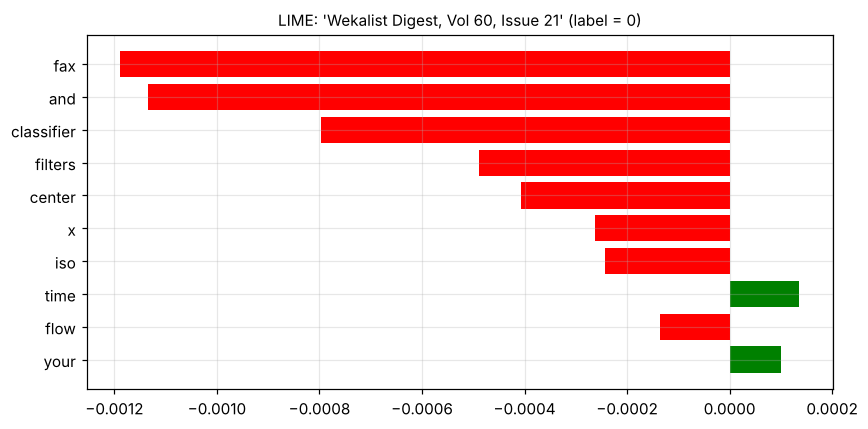

In [23]:
try:
    from lime.lime_text import LimeTextExplainer
    explainer = LimeTextExplainer(class_names=["legitimate", "phishing"], random_state=SEED)
    lime_fn = lambda texts: np.column_stack([1 - detector.predict_proba(list(texts)),
                                             detector.predict_proba(list(texts))])
    for ex in [ph_ex, lg_ex]:
        exp = explainer.explain_instance(ex.text, lime_fn, num_features=10, num_samples=1000)
        fig = exp.as_pyplot_figure(label=1)
        fig.set_size_inches(8, 4)
        plt.title(f"LIME: '{str(ex.subject)[:50]}' (label = {ex.label})", fontsize=10)
        plt.tight_layout(); plt.show()
except ImportError:
    print("LIME is not installed. Run `pip install lime` to see LIME explanations (occlusion results above still apply).")

## 14. Sanity check on hand-written emails

These emails were written for this test and are **not** from any dataset. The last column shows what our **first version** of the model (trained on CEAS_08 with spam as the positive class) said about the same emails. That version missed the PayPal credential-phishing email completely.

,subject,BiLSTM P(phish),BiLSTM,baseline P(phish),baseline,first version P(phish),top BiLSTM words
0,Your PayPal account has been limited,1.0000,phishing,0.9982,phishing,0.0043,"your, account"
1,URGENT: Your mailbox is full,0.9999,phishing,0.9121,phishing,0.9961,"upgrade, your, now"
2,FNB: Online banking access suspended,0.9996,phishing,0.9513,phishing,not tested,"your, banking"
3,Your Microsoft 365 password expires today,0.9963,phishing,0.9084,phishing,not tested,"your, password, will"
4,Cheap replica watches - 80% off,0.0000,legitimate,0.0293,legitimate,1.0,%
5,Re: group project meeting on Thursday,0.0001,legitimate,0.0238,legitimate,0.0018,we
6,Re: [Python-Dev] patch review for issue 2291,0.0000,legitimate,0.0083,legitimate,0.0,we


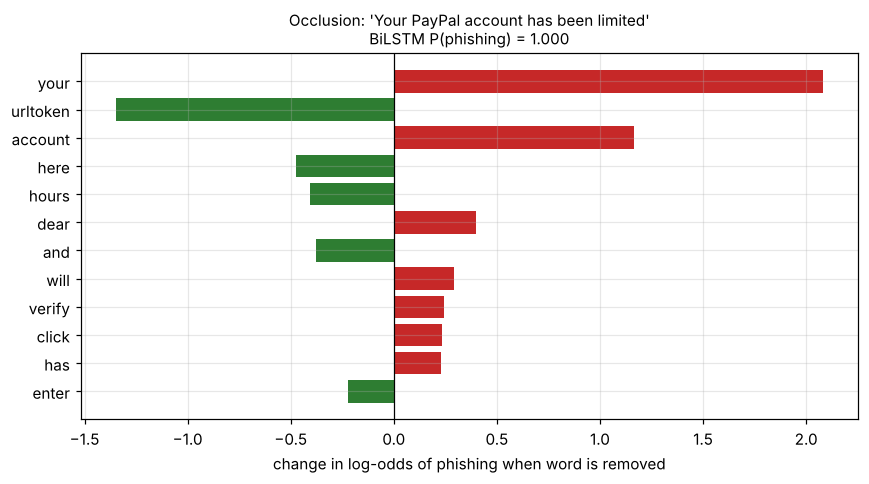

In [24]:
samples = [
    ("Your PayPal account has been limited",
     "Dear customer, we noticed unusual activity on your account. Please verify your identity within 24 hours "
     "or your account will be suspended. Click here: http://paypal-secure-verify.com/login and enter your password."),
    ("URGENT: Your mailbox is full",
     "Your email quota has exceeded the limit. Click http://webmail-upgrade.net to upgrade now or lose all messages!!!"),
    ("FNB: Online banking access suspended",
     "Dear client, your FNB online banking profile has been suspended due to a security update. "
     "Log in at http://fnb-secure-update.co.za/verify to confirm your card details and restore access."),
    ("Your Microsoft 365 password expires today",
     "Your password will expire in 24 hours. Keep your current password by confirming your login here: "
     "http://office365-keep-password.com"),
    ("Cheap replica watches - 80% off",
     "Buy luxury replica watches at the lowest prices! Rolex, Omega and more. Visit www.best-replicas.biz today!"),
    ("Re: group project meeting on Thursday",
     "Hi Wayne, can we move the ITRI625 meeting to 14:00? I pushed the notebook changes to GitHub. Thanks, Asemahle"),
    ("Re: [Python-Dev] patch review for issue 2291",
     "I looked at the patch and the tests pass on Linux. Could someone check the Windows build before we merge?"),
]
# P(phishing) from the first version of the model (CEAS_08 only, spam = positive), recorded before retraining
first_version = [0.0043, 0.9961, None, None, 1.0000, 0.0018, 0.0000]

rows = []
for (subj, body), old in zip(samples, first_version):
    r = detector.analyse(subj, body, top_k=5)
    b = detector.analyse(subj, body, model="baseline", top_k=5)
    rows.append({"subject": subj, "BiLSTM P(phish)": r["probability"], "BiLSTM": r["label"],
                 "baseline P(phish)": b["probability"], "baseline": b["label"],
                 "first version P(phish)": "not tested" if old is None else old,
                 "top BiLSTM words": ", ".join(t["token"] for t in r["top_tokens"] if t["weight"] > 0)})
display(pd.DataFrame(rows))

# Why did the BiLSTM decide what it did on the credential-phishing example?
fig, ax = plt.subplots(figsize=(8, 4.5))
r = detector.analyse(*samples[0], top_k=12)
plot_explanation(r["top_tokens"], f"Occlusion: '{samples[0][0]}'\nBiLSTM P(phishing) = {r['probability']:.3f}", ax)
plt.tight_layout(); savefig("xai_handwritten_phishing"); plt.show()

**How to read this.**
* The credential-phishing emails (PayPal, mailbox, FNB, Microsoft 365) should now be flagged. The first version missed the PayPal one, because its training data contained almost no credential theft.
* The **replica-watch spam** is *not* phishing under our new definition: it is advertising, not an attempt to steal credentials or money through deception. A low score for it is therefore expected, and correct for this model. Spam filtering is a separate task.
* The occlusion chart shows which words pushed the PayPal email towards phishing.

## 15. Summary

* The cell below prints the final numbers. The figures are also saved in `results/figures/`, and the per-epoch log in `results/metrics_log.csv`.
* The model is saved in `models/`. Start the API with `uvicorn api.main:app --reload` from the project root, then run `python app/desktop_app.py`.
* **Points for the theory report (3.3 / 3.4):**
  * **Defining the problem matters most.** Our first version, trained with spam as the positive class, scored above 99% but missed a basic PayPal phishing email. Re-defining the positive class as phishing and fraud (Nazario + Nigerian_Fraud) fixed this.
  * Removing duplicates before splitting matters: a large share of the raw corpora is duplicated.
  * **Shortcut learning** is a real risk when classes come from different corpora. We masked the Nazario collector's name and mixed legitimate mail from three corpora; the per-source table in Section 10.2 checks that every source is handled.
  * **Class imbalance:** phishing is the minority class, so we weighted the loss (`pos_weight`) and tuned the threshold on validation data. Accuracy alone is misleading here, so precision, recall, F1 and PR-AUC matter more.
  * **Concept drift:** even 2022 phishing will differ from tomorrow's (e.g. AI-written phishing). A deployed model needs regular retraining.
  * Trade-off between false positives and false negatives: the threshold can be moved (see the threshold plot), depending on whether missed phishing or blocked legitimate mail is more costly.

In [25]:
print("Best epoch:", stopper.best_epoch, "of", len(metrics_log), "| threshold:", round(THRESHOLD, 3))
display(results.style.format("{:.4f}"))

Best epoch: 4 of 7 | threshold: 0.695


,accuracy,precision,recall,f1,auc_roc,pr_auc
TF-IDF + LogReg (baseline),0.9946,0.9929,0.9748,0.9838,0.9996,0.9987
BiLSTM @ 0.5,0.9941,0.9739,0.9916,0.9827,0.9996,0.9986
BiLSTM @ tuned 0.695,0.9955,0.9833,0.9902,0.9868,0.9996,0.9986
